# Burn a landscape with pyretechnics

How `fb_tools` drives the pyretechnics engine, from a LANDFIRE landscape to probabilistic fire surfaces:

1. **Static layers** — de-stack the LCP into engine-unit rasters.
2. **Potential fire behavior** — a deterministic, FlamMap-style map under one weather state.
3. **Weather episodes** — real historical windows at a named ERC severity, with spatially resolved HRRR wind.
4. **Ignition sites** — drawn from an FPA-FOD ignition density grid, as FSim does.
5. **One realization** — ignite, spread, look at arrival time and flame length.
6. **Ensemble** — every site × every episode → burn probability, arrival probability by day, expected firebrands.

Runs in the `fb_pyre` env. Landscape: the `front_range` test AOI (pyrome 46, 3000 × 1000 cells at 30 m), downloaded
once with `lfps_request` into `data/spatial/mod/fuelscapes/front_range/`. Weather comes from the caches under
`data/weather/`. Products go to scratch (`$FB_PYRE_SCRATCH`, default `~/fb_scratch`); HRRR GRIB subsets go to the
shared cache every fb_tools HRRR fetch uses (`$FB_HRRR_CACHE`, default `~/fb_scratch/hrrr_cache`).

In [1]:
import json, os, time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import pandas as pd
import rasterio, rasterio.plot

import fb_tools
from fb_tools.models import pyre
from fb_tools.fuelscape import ignition_density_surface, sample_density_ignitions
from fb_tools.spread import (destack_lcp, select_episodes, load_rtma_hourly, write_episode_frames,
                             layer_bounds_lonlat, episode_wind_cube, write_wind_cube, load_wind_cube,
                             wind_cube_summary, weather_arrays, weather_from_scenario,
                             summarize_realization, summarize_runs, aggregate_realizations)
from fb_tools.weather import fetch_hrrr_wind_grid, dominant_wind_direction, default_hrrr_cache

REPO         = Path(fb_tools.__file__).resolve().parents[1]
LCP_FP       = next((REPO / "data/spatial/mod/fuelscapes/front_range").glob("LCP_front_range_LF*.tif"))
SCRATCH      = Path(os.environ.get("FB_PYRE_SCRATCH", Path.home() / "fb_scratch")) / "pyre_example"
ERC_DIR      = REPO / "data/weather/pyrome_erc"                       # GridMET ERC climatology (00a)
RTMA_DIR     = REPO / "data/weather/pyrome_emc/RTMA_MONTHLY"          # hourly T/RH, pyrome mean (00b)
WIND_DIR     = REPO / "data/weather/pyrome_emc/RTMA_WIND_MONTHLY"     # hourly u/v, pyrome mean (00b)
WINDCELL_DIR = REPO / "data/weather/pyrome_wind"                      # HRRR fire-hour wind climatology (00c)
FOD_FP       = Path("/Users/mcc/Library/CloudStorage/Box-Box/MCC/data/wildfire/FPA_FOD/"
                    "RDS-2013-0009/Data/FPA_FOD_20260615.gpkg")       # authoritative FPA-FOD, through 2024

PYROME          = 46
YEARS           = range(2016, 2026)   # HRRR is gap-free from 2016
SEVERITY        = "p97"               # ERC percentile that day 1 of an episode must meet
DURATION_DAYS   = 21
N_EPISODES      = 5
N_IGNITIONS     = 100
FOD_MIN_CLASS   = "D"                 # FPA-FOD size classes >= this (C = 10 ac+) build the ignition density grid
IDG_BANDWIDTH_M = 10_000              # Gaussian kernel sd of the ignition density grid
CROWN_GATE      = 0.0                 # canopy-cover gate for crown fire (0.0 = off; stock engine 0.4)
N_WORKERS       = 6
SEED            = 617327

pyre.pyre_version_info()

{'pyretechnics_version': '2026.8.10+cfri1',
 'pyretechnics_pinned': '2026.8.10',
 'pyretechnics_patched': True,
 'crown_cover_threshold': 0.4,
 'python_version': '3.11.16',
 'numpy_version': '1.26.4',
 'scipy_version': '1.12.0',
 'platform': 'Darwin-arm64',
 'conda_env': 'fb_pyre'}

## 1. Static layers

`destack_lcp` writes one GeoTIFF per engine input, in engine units (slope as rise/run, canopy cover as a
fraction, heights in metres). `load_static_layers` reads them back as the arrays the cubes are built from.

In [2]:
layers = SCRATCH / "layers" / LCP_FP.stem
if not (layers / "fuel_model.tif").exists():
    destack_lcp(LCP_FP, layers)
static, TRANSFORM, CRS = pyre.load_static_layers(layers)
SHAPE = static["slope"].shape
print(SHAPE, CRS, f"{abs(TRANSFORM.a):.0f} m |", ", ".join(static))

(3000, 1000) EPSG:5070 30 m | slope, aspect, fuel_model, canopy_cover, canopy_height, canopy_base_height, canopy_bulk_density


## 2. Potential fire behavior (no spread)

A deterministic map from the engine's `burn_cells`: every cell burned as a head fire under one weather state.
Here the state is the pyrome's `p97` FlamMap scenario (RTMA dead fuel moisture, HRRR p97 wind speed), blowing
from the pyrome's dominant fire-hour direction — so the map is parameterized exactly like the FlamMap runs it
sits beside. `burn_landscape` writes flame length, fireline intensity, spread rate/direction and fire type.

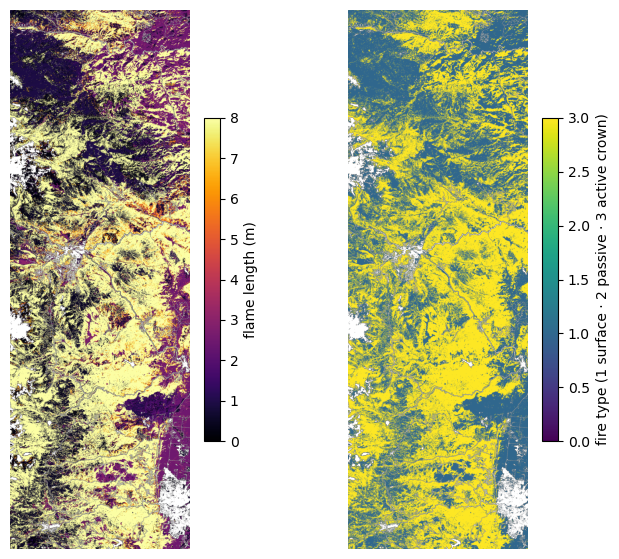

wind from 292° at 43 km/h | {'n_burnable': 2792165, 'crown_frac': 0.5272, 'wall_s': 2.0}


In [3]:
def show(ax, fp, label, *, mask_zero=False, **kw):
    """imshow one GeoTIFF band with a colorbar."""
    with rasterio.open(fp) as src:
        a = src.read(1)
        if mask_zero:
            a = np.where(a > 0, a, np.nan)
        im = ax.imshow(a, extent=rasterio.plot.plotting_extent(src), **kw)
    plt.colorbar(im, ax=ax, shrink=0.6, label=label); ax.set_axis_off()
    return ax

def zoom(ax, fp, margin_cells=60):
    """Limit the axes to the finite (burned) cells of a raster, plus a margin."""
    with rasterio.open(fp) as src:
        rr, cc = np.where(np.isfinite(src.read(1)))
        x0, y0 = src.xy(rr.max() + margin_cells, cc.min() - margin_cells)
        x1, y1 = src.xy(rr.min() - margin_cells, cc.max() + margin_cells)
    ax.set(xlim=(x0, x1), ylim=(y0, y1))

p97 = json.load(open(REPO / f"data/weather/flammap_rtma/pyrome_{PYROME}_flammap.json"))["scenarios"]["p97"]
WD_FROM = dominant_wind_direction(PYROME, WINDCELL_DIR)
scen = weather_from_scenario(p97, wind_from_deg=WD_FROM, tmp_c=30.0)
pot_dir = SCRATCH / f"potential_p97_wd{WD_FROM:.0f}"          # named by its inputs: a cached map is never stale
pot = pyre.burn_landscape(layers, scen, pot_dir, crown_gate=CROWN_GATE)

fig, axes = plt.subplots(1, 2, figsize=(8, 7))
show(axes[0], pot_dir / "flame_length.tif", "flame length (m)", cmap="inferno", vmin=0, vmax=8)
show(axes[1], pot_dir / "fire_type.tif", "fire type (1 surface · 2 passive · 3 active crown)",
     cmap="viridis", vmin=0, vmax=3)
plt.show()
print(f"wind from {WD_FROM:.0f}° at {scen['wind_speed_10m'][0]:.0f} km/h |",
      {k: pot[k] for k in ("n_burnable", "crown_frac", "wall_s")})

## 3. Weather episodes

An *episode* is a real historical window whose day-1 ERC meets the severity percentile of the pyrome's GridMET
climatology — nothing is scaled or offset, so each episode is nameable and keeps its diurnal cycle and
day-to-day autocorrelation. Hourly T/RH from the pyrome-mean RTMA record are turned into NFDRS dead fuel
moisture; the hourly frame is written in engine units (°C, km/h, moistures as fractions). Windows with an RTMA
gap longer than 3 h are never candidates.

[select_episodes] 38 windows meet p97; 37 also have RTMA coverage (gaps <= 3 h)


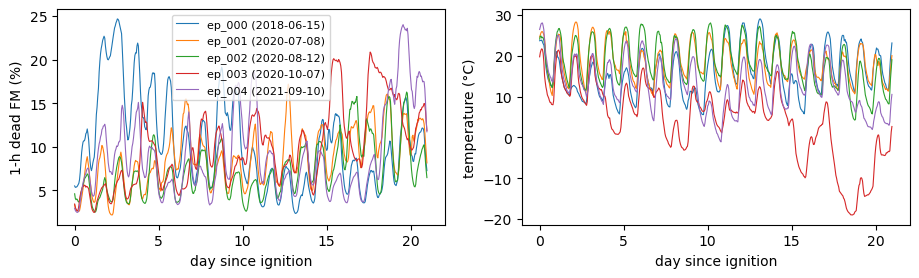

,episode_id,start_date,end_date,erc_day1,erc_mean,erc_threshold
0,ep_000,2018-06-15,2018-07-05,75.0,60.0,74.0
1,ep_001,2020-07-08,2020-07-28,75.0,66.8,74.0
2,ep_002,2020-08-12,2020-09-01,76.0,71.0,74.0
3,ep_003,2020-10-07,2020-10-27,79.0,64.7,74.0
4,ep_004,2021-09-10,2021-09-30,76.0,61.6,74.0


In [4]:
rtma = load_rtma_hourly(RTMA_DIR, PYROME, YEARS, wind_dir=WIND_DIR)
episodes = select_episodes(PYROME, ERC_DIR, severity=SEVERITY, n=N_EPISODES, duration_days=DURATION_DAYS,
                           years=YEARS, rtma_df=rtma, seed=SEED)
frames = write_episode_frames(episodes, rtma, SCRATCH / "episodes")          # {episode_id: hourly csv}

fig, axes = plt.subplots(1, 2, figsize=(11, 2.8))
for eid, fp in frames.items():
    f = pd.read_csv(fp)
    axes[0].plot(f.hour / 24, f.fm1 * 100, lw=0.8, label=f"{eid} ({episodes.set_index('episode_id').start_date[eid]:%Y-%m-%d})")
    axes[1].plot(f.hour / 24, f.tmp_c, lw=0.8)
axes[0].set(ylabel="1-h dead FM (%)", xlabel="day since ignition"); axes[1].set(ylabel="temperature (°C)", xlabel="day since ignition")
axes[0].legend(fontsize=8); plt.show()
episodes[["episode_id", "start_date", "end_date", "erc_day1", "erc_mean", "erc_threshold"]]

+---
### 3b. Local wind

Any spatial mean of wind erases the gusts that drive spread: the pyrome-mean wind rarely exceeds 17 mph while
single 3 km HRRR cells in the same domain reach 30. So each episode's wind is a 3-D cube: HRRR 10 m U/V fetched
by HTTP byte range from AWS (~2 MB per hour, cached once for every fb_tools HRRR user), sampled nearest-cell onto
a block grid that divides the landscape exactly. The engine repeats each block over its 30 m cells; T/RH stay on
the pyrome-mean frame.

[fetch_hrrr_wind_grid] 504 h, 35x20 cells, 0 missing hour(s) interpolated


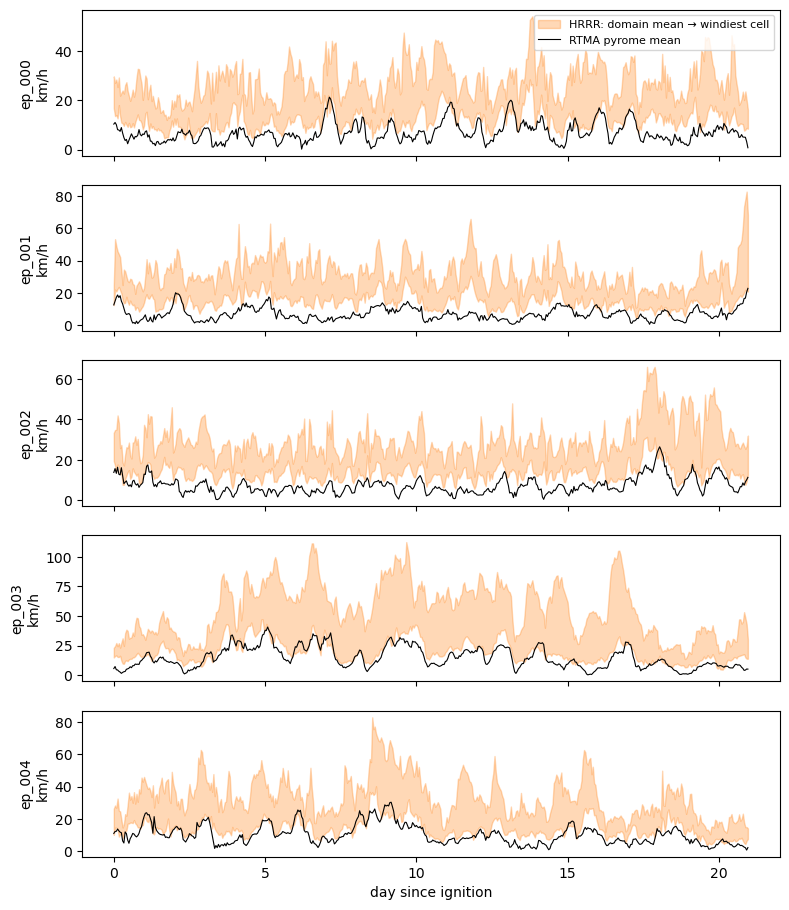

cube (504, 30, 10) | block (100, 100) cells = (3000.0, 3000.0) m | HRRR cache: /Users/mcc/fb_scratch/hrrr_cache


In [5]:
bounds = layer_bounds_lonlat(layers)
cubes = {}
for eid, fp in frames.items():
    times = pd.read_csv(fp, parse_dates=["datetime_utc"]).datetime_utc
    cube_fp = SCRATCH / "episodes" / f"{eid}_{times.iloc[0]:%Y%m%d}_wind.npz"   # dated: a re-selected ep_000 never reuses a stale cube
    if not cube_fp.exists():
        grid = fetch_hrrr_wind_grid(times, bounds, n_threads=6)              # -> default_hrrr_cache()
        write_wind_cube(cube_fp, episode_wind_cube(grid, TRANSFORM, CRS, SHAPE))
    cubes[eid] = cube_fp

fig, axes = plt.subplots(len(cubes), 1, figsize=(9, 2.2 * len(cubes)), sharex=True, squeeze=False)
for ax, (eid, fp) in zip(axes[:, 0], cubes.items()):
    s, f = wind_cube_summary(load_wind_cube(fp)), pd.read_csv(frames[eid])
    ax.fill_between(s.hour / 24, s.ws_mean, s.ws_max, color="C1", alpha=0.3, label="HRRR: domain mean → windiest cell")
    ax.plot(f.hour / 24, f.ws_kmh, color="k", lw=0.8, label="RTMA pyrome mean")
    ax.set(ylabel=f"{eid}\nkm/h")
axes[0, 0].legend(loc="upper right", fontsize=8); axes[-1, 0].set(xlabel="day since ignition"); plt.show()
c = load_wind_cube(next(iter(cubes.values())))
print("cube", c["wind_speed_10m"].shape, "| block", c["block"], "cells =", c["block_m"], "m | HRRR cache:", default_hrrr_cache())

## 4. Ignition sites from an ignition density grid

FSim does not place fires uniformly: it draws locations from an **ignition density grid** (IDG), a
kernel-smoothed surface of historical FPA-FOD ignitions masked to burnable fuel. `ignition_density_surface`
builds the same thing from the authoritative FOD (through 2024): fires of size class ≥ `FOD_MIN_CLASS` in and
around the landscape (points outside the domain still contribute smoothing mass at its edge), a Gaussian kernel
of `IDG_BANDWIDTH_M`, normalized to sum to 1 over burnable cells. `sample_density_ignitions` then draws
`N_IGNITIONS` **grid cells** ∝ density without replacement — any burnable cell that received kernel mass can be
drawn, so sites are *not* the historical points themselves — and writes each as a 10-acre day-1 footprint in its
own shapefile. Because sites are drawn ∝ density, every realization carries equal weight in the ensemble.

`FOD_MIN_CLASS = "C"` keeps fires of 10 acres and up: the places fires *grew*, not merely started. The
front_range window holds a few hundred such fires, so the kernel is wider (10 km) than it would be for all
ignitions; widen it further for class D+ (100 ac+, ~160 points here) or the surface turns into a few spikes.

Two things FSim does that this example does not: the number of fires per simulated day is drawn from an
ERC-conditioned occurrence model (here the count is fixed), and ignitions are spread through a whole season
(here they all start on day 1 of a severe episode).

  [ignition_density_surface] bandwidth=10,000 m (4.0 cells), 74 points (25 inside the LCP), burnable-masked, normalized
  [write_ignition_shapefiles] 100 single-feature shapefile(s) → /Users/mcc/fb_scratch/pyre_example/ignitions
  [sample_density_ignitions] 100 site(s) drawn ∝ density (10.00 ac each) → /Users/mcc/fb_scratch/pyre_example/ignitions


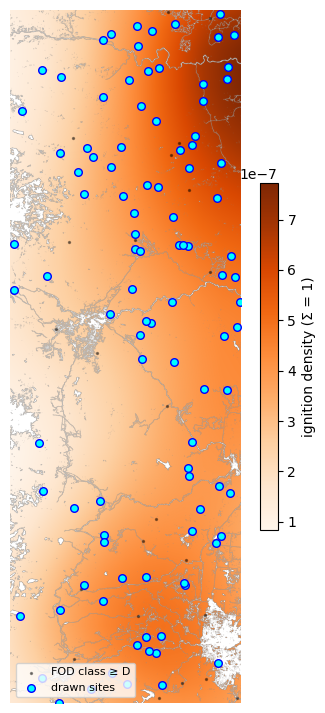

25 FOD fires inside the landscape (159 in the smoothing window); 100 sites drawn (10.00 ac each), w_i = 1/100


,geometry,ign_id,density,w_i,footprint_ac,path
0,"POLYGON ((-795126.503 1935630, -795126.537 193...",0,4.389882e-07,0.01,9.999,/Users/mcc/fb_scratch/pyre_example/ignitions/i...
1,"POLYGON ((-791466.503 1968720, -791466.537 196...",1,3.467220e-07,0.01,9.999,/Users/mcc/fb_scratch/pyre_example/ignitions/i...
2,"POLYGON ((-797706.503 1998120, -797706.537 199...",2,3.286558e-07,0.01,9.999,/Users/mcc/fb_scratch/pyre_example/ignitions/i...
3,"POLYGON ((-781146.503 1946640, -781146.537 194...",3,3.835054e-07,0.01,9.999,/Users/mcc/fb_scratch/pyre_example/ignitions/i...
4,"POLYGON ((-800136.503 1934670, -800136.537 193...",4,3.758192e-07,0.01,9.999,/Users/mcc/fb_scratch/pyre_example/ignitions/i...


In [6]:
with rasterio.open(LCP_FP) as src:
    B = src.bounds
box = gpd.GeoSeries.from_xy([B.left, B.right], [B.bottom, B.top], crs=CRS).to_crs(4269)
pad = 0.6                                                   # degrees, ~10 bandwidths: edge smoothing is honest
classes = ", ".join(repr(c) for c in "ABCDEFG" if c >= FOD_MIN_CLASS)
fod = gpd.read_file(FOD_FP, layer="Fires", where=f"FIRE_SIZE_CLASS IN ({classes})",
                    bbox=(box.x.min() - pad, box.y.min() - pad, box.x.max() + pad, box.y.max() + pad))
idg = ignition_density_surface(fod, LCP_FP, bandwidth_m=IDG_BANDWIDTH_M)
ign = sample_density_ignitions(idg, N_IGNITIONS, SCRATCH / "ignitions", seed=SEED)

fig, ax = plt.subplots(figsize=(5, 9))
im = ax.imshow(np.where(idg["density"] > 0, idg["density"], np.nan),
               extent=rasterio.plot.plotting_extent(idg["density"], idg["transform"]), cmap="Oranges")
fod.to_crs(CRS).cx[B.left:B.right, B.bottom:B.top].plot(ax=ax, markersize=2, color="k", alpha=0.4,
                                                        label=f"FOD class ≥ {FOD_MIN_CLASS}")
ign.centroid.plot(ax=ax, color="cyan", edgecolor="b", markersize=30, label="drawn sites")
ax.legend(loc="lower left", fontsize=8); ax.set_axis_off()
plt.colorbar(im, ax=ax, shrink=0.5, label="ignition density (Σ = 1)"); plt.show()
print(f"{idg['n_in_domain']} FOD fires inside the landscape ({len(fod)} in the smoothing window); "
      f"{len(ign)} sites drawn ({ign.footprint_ac.iloc[0]:.2f} ac each), w_i = 1/{len(ign)}")
ign.head()

## 5. One realization

`run_realization` takes one landscape, one weather set (hourly frame + wind cube) and one footprint, and writes
arrival time (minutes), fire type, spread rate/direction, fireline intensity and flame length as GeoTIFFs plus
a manifest that records the seed, engine build, crown gate and solver knobs. Spotting is on with the engine's
default parameters (`SPOT_CENTRAL`). It is a heavy tail: most seeds add little area, a few break out — so the
single run below is one draw, not the answer.

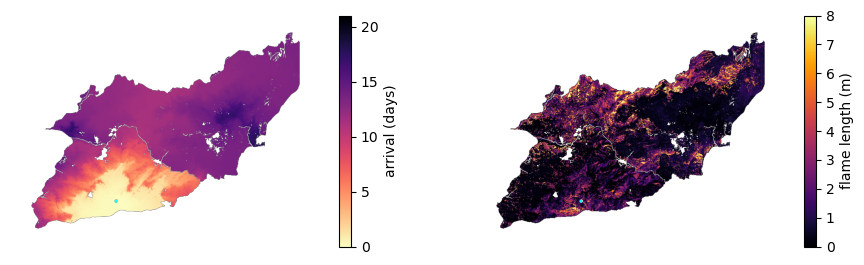

26.1 s | burned 18,197 ha | max duration reached | pending spot cells 0 | engine 2026.8.10+cfri1


arm                   None
ignition_id        ign_000
episode_id          ep_000
condition_id          None
seed             132185622
burned_ha         18197.19
crown_frac          0.3267
fl_p95_m              5.05
fi_p95_kw_m         8798.0
max_toa_h            447.4
firebrands      129.140125
area_d1_ha         1327.05
area_d3_ha         2042.28
area_d7_ha         4008.15
dtype: object

In [7]:
ep0, site = next(iter(frames)), ign.iloc[0]
run_dir = SCRATCH / "runs" / "single" / f"{ep0}_ign_{site.ign_id:03d}"
man = pyre.run_realization(layers, weather_arrays(pd.read_csv(frames[ep0]), wind_cube=cubes[ep0]), site.path, run_dir,
                           seed=pyre.seed_for(SEED, f"ign_{site.ign_id:03d}", ep0, "central"),
                           duration_h=DURATION_DAYS * 24, spot_config=pyre.SPOT_CENTRAL, crown_gate=CROWN_GATE,
                           meta={"ignition_id": f"ign_{site.ign_id:03d}", "episode_id": ep0})

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
with rasterio.open(run_dir / "time_of_arrival.tif") as src:
    im = axes[0].imshow(src.read(1) / 1440.0, extent=rasterio.plot.plotting_extent(src), cmap="magma_r", vmin=0, vmax=DURATION_DAYS)
plt.colorbar(im, ax=axes[0], shrink=0.6, label="arrival (days)"); axes[0].set_axis_off()
show(axes[1], run_dir / "flame_length.tif", "flame length (m)", cmap="inferno", vmin=0, vmax=8)
for ax in axes:
    gpd.read_file(site.path).plot(ax=ax, color="cyan"); zoom(ax, run_dir / "time_of_arrival.tif")
plt.show()
print(f"{man['wall_s']} s | burned {man['burned_ha']:,.0f} ha | {man['stop_condition']} | "
      f"pending spot cells {man['pending_spot_cells']} | engine {man['pyretechnics_version']}")
pd.Series(summarize_realization(run_dir, day_marks=(1, 3, 7)))

## 6. Ensemble → probabilistic surfaces

`build_runs` crosses every ignition × episode × condition (× arm) into one table, with a deterministic seed
per (ignition, episode, condition). The seed never depends on the arm, so adding a treated landscape later
gives exactly paired runs. `run_batch` runs the table in a spawn pool and skips rows whose manifest already
exists. `aggregate_realizations` streams the results into

- **BurnProb** — fraction of realizations that burned the cell;
- **ArrivalProb_d{d}** — fraction that reached the cell by day *d*: the probabilistic arrival-time surface;
- **AvgTime**, **AvgFlameLength** — mean arrival day and flame length where burned;
- **Firebrands** — expected firebrands produced per cell, averaged over realizations: the engine's production
  formula (*f* · 60 *I* / *R* · cell area) read off each realization's intensity and spread-rate rasters. This
  is a spot-fire **source** map; realized ember landings are not exposed by the engine's final matrices.

With one arm and sites drawn ∝ density these are probabilities over ignition location and over `SEVERITY`
weather, conditional on a fire starting on day 1 of a severe episode.

In [8]:
runs = pyre.build_runs(arms={"baseline": layers},
                       ignitions={f"ign_{i:03d}": p for i, p in zip(ign.ign_id, ign.path)},
                       episodes=frames, wind_cubes=cubes,
                       conditions={"central": {"spot_config": pyre.SPOT_CENTRAL, "crown_gate": CROWN_GATE}},
                       base_seed=SEED, out_root=SCRATCH / "runs" / "ensemble")
print(len(runs), "realizations =", ign.shape[0], "sites ×", len(frames), "episodes")
t0 = time.perf_counter()
res = pyre.run_batch(runs, duration_h=DURATION_DAYS * 24, n_workers=N_WORKERS)
print(f"{(time.perf_counter() - t0) / 60:.1f} min wall on {N_WORKERS} workers")
summary = summarize_runs(res, day_marks=(1, 3, 7, 15, 21))
summary[["burned_ha", "area_d1_ha", "area_d3_ha", "fl_p95_m", "firebrands"]].describe(percentiles=[.5, .9]).round(1)

500 realizations = 100 sites × 5 episodes
[run_batch] 50/500
[run_batch] 100/500
[run_batch] 150/500
[run_batch] 200/500
[run_batch] 250/500
[run_batch] 300/500
[run_batch] 350/500
[run_batch] 400/500
[run_batch] 450/500
[run_batch] 500/500
[run_batch] 495/500 ok, 5 errors, 709.6 min compute
  baseline/ign_054/ep_000: RuntimeError: Realization did not spread beyond the ignition (7 cells)
  baseline/ign_054/ep_001: RuntimeError: Realization did not spread beyond the ignition (7 cells)
  baseline/ign_054/ep_002: RuntimeError: Realization did not spread beyond the ignition (7 cells)
  baseline/ign_054/ep_003: RuntimeError: Realization did not spread beyond the ignition (7 cells)
  baseline/ign_054/ep_004: RuntimeError: Realization did not spread beyond the ignition (7 cells)
120.8 min wall on 6 workers


,burned_ha,area_d1_ha,area_d3_ha,fl_p95_m,firebrands
count,495.0,495.0,495.0,495.0,495.0
mean,29150.2,2941.8,8268.1,6.2,245.8
std,19719.6,3145.9,7917.6,1.5,177.1
min,231.8,5.8,14.2,0.5,0.4
50%,28008.0,1963.1,5985.1,6.2,219.3
90%,55068.6,6948.3,19950.3,8.2,492.3
max,85897.2,19188.7,55182.0,10.4,1039.2


[aggregate_realizations] 495 realizations -> /Users/mcc/fb_scratch/pyre_example/ensemble (BurnProb, AvgFlameLength, AvgTime, n_burned, ArrivalProb_d1, ArrivalProb_d3, ArrivalProb_d7, Firebrands)


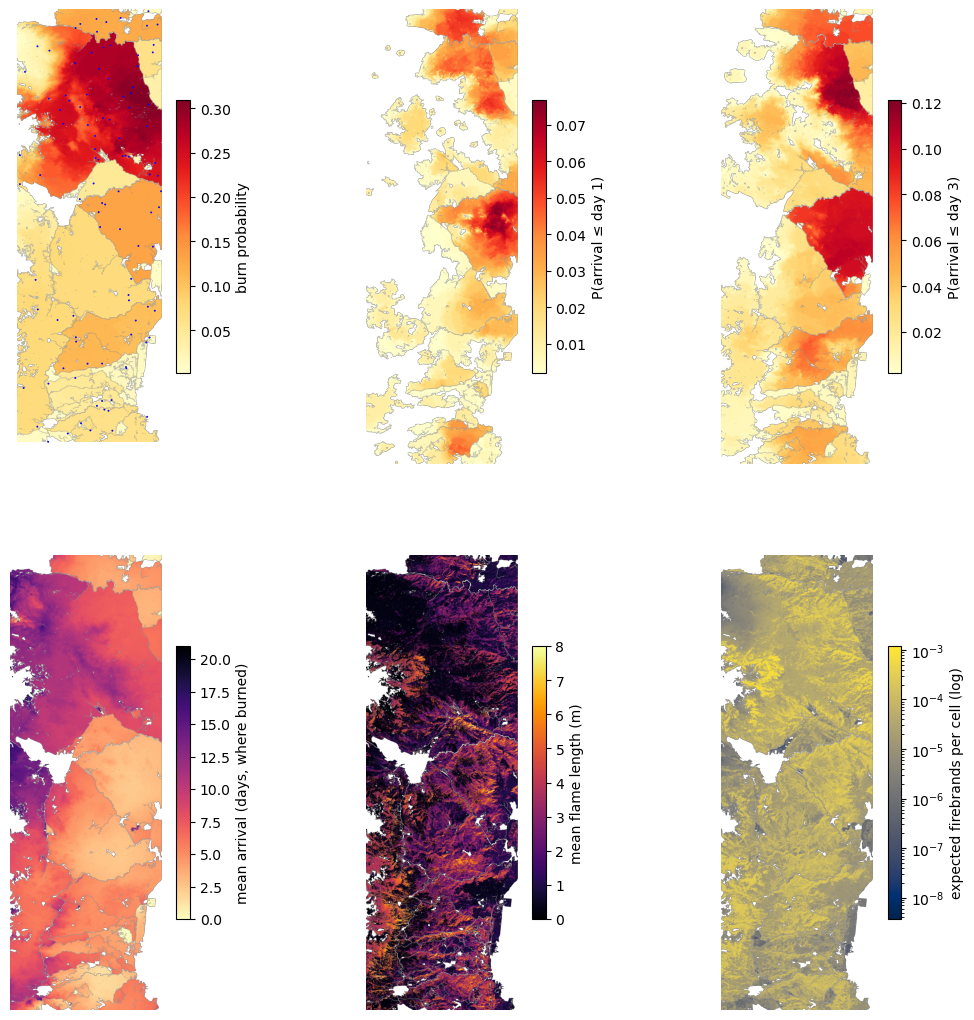

BurnProb > 0 on 237,728 ha; mean fire size 29,150 ha; Σ BP × area = 29,150 ha (the two agree by construction)


In [9]:
agg = aggregate_realizations(res.loc[res.status == "ok", "out_dir"], SCRATCH / "ensemble", day_marks=(1, 3, 7))

fig, axes = plt.subplots(2, 3, figsize=(13, 13))
show(axes[0, 0], agg["BurnProb"], "burn probability", mask_zero=True, cmap="YlOrRd")
ign.plot(ax=axes[0, 0], color="none", edgecolor="b", lw=0.6)
show(axes[0, 1], agg["ArrivalProb_d1"], "P(arrival ≤ day 1)", mask_zero=True, cmap="YlOrRd")
show(axes[0, 2], agg["ArrivalProb_d3"], "P(arrival ≤ day 3)", mask_zero=True, cmap="YlOrRd")
show(axes[1, 0], agg["AvgTime"], "mean arrival (days, where burned)", cmap="magma_r", vmin=0, vmax=DURATION_DAYS)
show(axes[1, 1], agg["AvgFlameLength"], "mean flame length (m)", cmap="inferno", vmin=0, vmax=8)
show(axes[1, 2], agg["Firebrands"], "expected firebrands per cell (log)", mask_zero=True, cmap="cividis", norm=LogNorm())
plt.show()
with rasterio.open(agg["BurnProb"]) as src:
    bp = src.read(1)
print(f"BurnProb > 0 on {(bp > 0).sum() * 0.09:,.0f} ha; mean fire size {summary.burned_ha.mean():,.0f} ha; "
      f"Σ BP × area = {bp.sum() * 0.09:,.0f} ha (the two agree by construction)")

## Next

- **Counterfactual:** add a second `arms` entry (a treated LCP on the same grid). Same seeds and weather →
  exact pairing; `paired_deltas` on the summaries and per-arm `aggregate_realizations` give Δ surfaces. The
  COSWAP project notebook `05_PyreTransmission.ipynb` is the worked example.
- **More realizations.** 90 runs is a demonstration, not a production surface. On this grid a 7-day
  realization costs ~4.5 s of wall time on 4 workers, so 1,000 runs is ~75 min and 5,000 about 6 h; raise
  `N_IGNITIONS` first (location is the larger source of variance here), then `N_EPISODES`. Check convergence
  by aggregating two random halves of `res` separately and comparing their `BurnProb` rasters: the ensemble is
  large enough when the half-to-half difference is smaller than the effect you want to read.
- **Toward FSim:** draw episodes across severities with ERC-conditioned fire counts instead of `p97` only, and
  spread ignitions through the season.
- **Domain:** trust BurnProb near the boundary only after an edge check (`check_domain_adequacy`-style);
  fires that reach the edge are truncated, not stopped.